## Models

In [4]:
import os
import warnings
import joblib
import json
import logging

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns


# ____ Sklearn — prétraitement et pipeline ____

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.model_selection import (
    train_test_split,
    KFold,
    TimeSeriesSplit,
    GridSearchCV,
    RandomizedSearchCV,
    cross_validate,
    cross_val_score,
    learning_curve
)

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    root_mean_squared_error
)

from sklearn.inspection import permutation_importance


# ____ Sklearn — modèles ____
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# ____ XGBoost ____
from xgboost import XGBRegressor

# ____ MLflow ____
import mlflow
import mlflow.sklearn

# ____ Warnings ____
warnings.filterwarnings("ignore")

# ____ Reproductibilité ____
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# ____ Configuration MLflow ____
logging.getLogger("mlflow").setLevel(logging.ERROR)

print("✅ Imports effectués avec succès.")

✅ Imports effectués avec succès.


In [6]:
# Configuration MLflow

MLFLOW_EXPERIMENT_NAME = "agritech-prediction"

mlflow.set_tracking_uri("mlruns")
mlflow.set_experiment(MLFLOW_EXPERIMENT_NAME)

print(f"Expérience MLflow configurée : '{MLFLOW_EXPERIMENT_NAME}'")
print(f"URI de tracking : mlruns/")

Expérience MLflow configurée : 'agritech-prediction'
URI de tracking : mlruns/


In [8]:
# Chargement du dataset principal
DATASET_PATH = r"C:\Users\amela\P12 System recomendation\outputs\dataset_final.csv"

df = pd.read_csv(DATASET_PATH)

print(f"Dimensions : {df.shape}")
print(f"Colonnes   : {list(df.columns)}")

df.head()

Dimensions : (13130, 7)
Colonnes   : ['Area', 'Item', 'Year', 'Yield_crops_hg_per_ha', 'average_rain_fall_mm_per_year', 'Pesticide_totale_use_tonnes', 'avg_temp']


,Area,Item,Year,Yield_crops_hg_per_ha,average_rain_fall_mm_per_year,Pesticide_totale_use_tonnes,avg_temp
0,Albania,Maize,1990,36613,1485.0,121.0,16.37
1,Albania,Maize,1991,29068,1485.0,121.0,15.36
2,Albania,Maize,1992,24876,1485.0,121.0,16.06
3,Albania,Maize,1993,24185,1485.0,121.0,16.05
4,Albania,Maize,1994,25848,1485.0,201.0,16.96


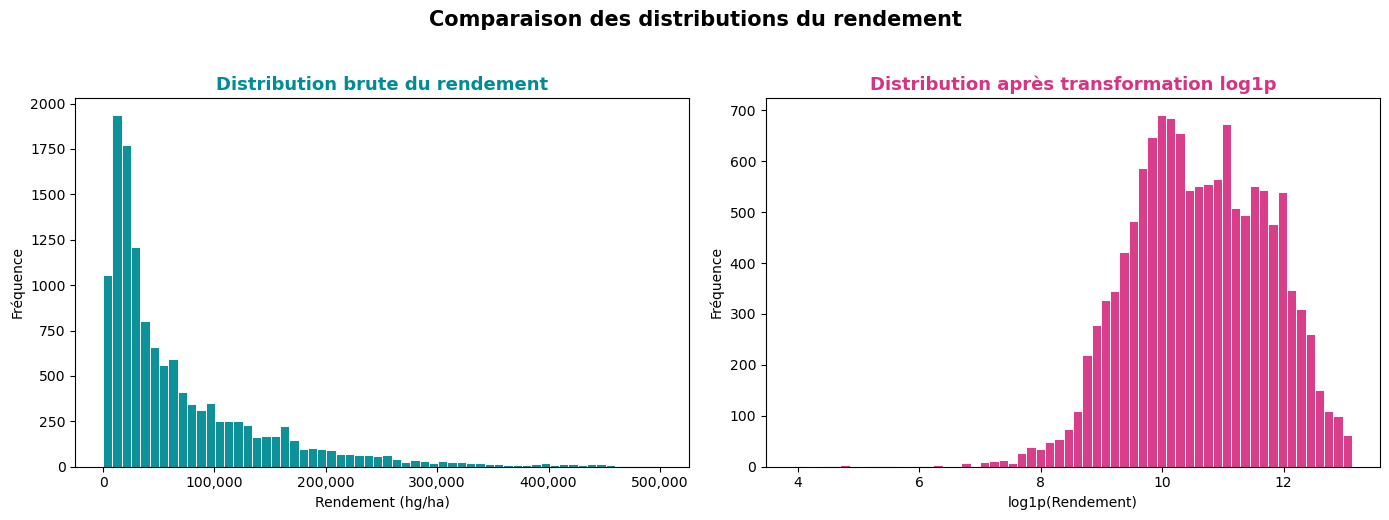

Skewness brut  : 2.0768
Skewness log1p : -0.2225


In [14]:
# Comparaison : distribution brute vs log-transformée

# Palette : bleu canard et fuchsia
bleu_canard = "#008C95"
fuchsia = "#D63384"

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribution brute — bleu canard
axes[0].hist(
    df["Yield_crops_hg_per_ha"],
    bins=60,
    color=bleu_canard,
    edgecolor="white",
    linewidth=0.7,
    alpha=0.95
)
axes[0].set_title(
    "Distribution brute du rendement",
    fontsize=13,
    fontweight="bold",
    color=bleu_canard
)
axes[0].set_xlabel("Rendement (hg/ha)")
axes[0].set_ylabel("Fréquence")
axes[0].xaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f"{int(x):,}")
)

# Distribution après transformation log1p — fuchsia
axes[1].hist(
    np.log1p(df["Yield_crops_hg_per_ha"]),
    bins=60,
    color=fuchsia,
    edgecolor="white",
    linewidth=0.7,
    alpha=0.95
)
axes[1].set_title(
    "Distribution après transformation log1p",
    fontsize=13,
    fontweight="bold",
    color=fuchsia
)
axes[1].set_xlabel("log1p(Rendement)")
axes[1].set_ylabel("Fréquence")

# Titre général
plt.suptitle(
    "Comparaison des distributions du rendement",
    fontsize=15,
    fontweight="bold",
    y=1.03
)

plt.tight_layout()

# Enregistrement du graphique
plt.savefig(
    r"C:\Users\amela\P12 System recomendation\outputs\distrib_target.png",
    dpi=150,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# Comparaison de l'asymétrie
skew_brut = df["Yield_crops_hg_per_ha"].skew()
skew_log = np.log1p(df["Yield_crops_hg_per_ha"]).skew()

print(f"Skewness brut  : {skew_brut:.4f}")
print(f"Skewness log1p : {skew_log:.4f}")

### Preparation por train / test

In [17]:
# Définition des features et de la cible
features_cat = ["Area", "Item"]
features_num = ["Year", "average_rain_fall_mm_per_year", "Pesticide_totale_use_tonnes", "avg_temp"]
features_all = features_cat + features_num
target       = "Yield_crops_hg_per_ha"

# Application de la transformation log1p sur la cible
X = df[features_all].copy()
y = np.log1p(df[target])

print(f"Features catégorielles : {features_cat}")
print(f"Features numériques    : {features_num}")
print(f"Cible (log1p)          : {target}")
print(f"Shape X : {X.shape}")
print(f"Shape y : {y.shape}")
### 3.2 — 

Features catégorielles : ['Area', 'Item']
Features numériques    : ['Year', 'average_rain_fall_mm_per_year', 'Pesticide_totale_use_tonnes', 'avg_temp']
Cible (log1p)          : Yield_crops_hg_per_ha
Shape X : (13130, 6)
Shape y : (13130,)


In [35]:

import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

TARGET = "Yield_crops_hg_per_ha"

FEATURES = [
    "Area",
    "Item",
    "Year",
    "average_rain_fall_mm_per_year",
    "Pesticide_totale_use_tonnes",
    "avg_temp"
]

# 1. Vérifier les données
df_check = df.dropna(subset=FEATURES + [TARGET]).copy()

# 2. Séparation temporelle : passé pour le train, futur pour le test
ANNEE_LIMITE = 2008

train_df = df_check[df_check["Year"] <= ANNEE_LIMITE]
test_df = df_check[df_check["Year"] > ANNEE_LIMITE]

X_train_time = train_df[FEATURES]
X_test_time = test_df[FEATURES]

y_train_time = np.log1p(train_df[TARGET].astype(float))
y_test_time = np.log1p(test_df[TARGET].astype(float))

print("Années train :", train_df["Year"].min(),
      "-", train_df["Year"].max())
print("Années test  :", test_df["Year"].min(),
      "-", test_df["Year"].max())
print("Taille train :", len(train_df))
print("Taille test  :", len(test_df))

# 3. Entraîner un nouveau pipeline, sans toucher à l'ancien
rf_time = clone(rf_pipeline)
rf_time.fit(X_train_time, y_train_time)

# 4. Prédictions sur les années futures
pred_log = rf_time.predict(X_test_time)

# Métriques sur l'échelle log1p
print("\n--- TEST TEMPOREL : log1p ---")
print("RMSE :", round(np.sqrt(
    mean_squared_error(y_test_time, pred_log)
), 4))
print("MAE  :", round(
    mean_absolute_error(y_test_time, pred_log), 4
))
print("R²   :", round(
    r2_score(y_test_time, pred_log), 4
))

# 5. Métriques sur l'échelle originale
y_test_original = np.expm1(y_test_time)
pred_original = np.maximum(np.expm1(pred_log), 0)

print("\n--- TEST TEMPOREL : hg/ha ---")
print("RMSE :", round(np.sqrt(
    mean_squared_error(y_test_original, pred_original)
), 2))
print("MAE  :", round(
    mean_absolute_error(y_test_original, pred_original), 2
))
print("R²   :", round(
    r2_score(y_test_original, pred_original), 4
))

# Pourcentage de prédictions à ±10 %
y_true = np.asarray(y_test_original)
y_pred = np.asarray(pred_original)

precision_10 = np.mean(
    np.abs(y_true - y_pred) / np.maximum(np.abs(y_true), 1e-8)
    <= 0.10
) * 100

print("Prédictions à ±10 % :", round(precision_10, 2), "%")


Années train : 1990 - 2008
Années test  : 2009 - 2013
Taille train : 10193
Taille test  : 2937

--- TEST TEMPOREL : log1p ---
RMSE : 0.3171
MAE  : 0.1964
R²   : 0.9208

--- TEST TEMPOREL : hg/ha ---
RMSE : 24474.38
MAE  : 12226.57
R²   : 0.9215
Prédictions à ±10 % : 47.19 %


### Regression Lineaire 

In [37]:


# ============================================================
# RÉGRESSION LINÉAIRE — SÉPARATION TEMPORELLE + MLFLOW
# Train : années <= 2008
# Test  : années > 2008
# Cible : log1p(Yield_crops_hg_per_ha)
# ============================================================

import numpy as np
import pandas as pd
import mlflow
import mlflow.sklearn

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)
from mlflow.models import infer_signature


# ============================================================
# 1. CONFIGURATION
# ============================================================

ANNEE_LIMITE = 2008
TARGET = "Yield_crops_hg_per_ha"

MLFLOW_EXPERIMENT_NAME = "agritech-prediction"

# Désactiver l'autologging pour éviter les doublons MLflow
mlflow.sklearn.autolog(disable=True)
mlflow.set_experiment(MLFLOW_EXPERIMENT_NAME)


# ============================================================
# 2. DÉFINITION DES VARIABLES
# ============================================================

num_features = [
    "Year",
    "average_rain_fall_mm_per_year",
    "Pesticide_totale_use_tonnes",
    "avg_temp"
]

cat_features = ["Area", "Item"]

FEATURES = cat_features + num_features

# Vérification des colonnes nécessaires
colonnes_requises = FEATURES + [TARGET]
colonnes_manquantes = [
    col for col in colonnes_requises if col not in df.columns
]

if colonnes_manquantes:
    raise ValueError(
        f"Colonnes manquantes dans df : {colonnes_manquantes}"
    )

# Nettoyage des valeurs manquantes et infinies
df_model = df[colonnes_requises].copy()

df_model = df_model.replace([np.inf, -np.inf], np.nan)
df_model = df_model.dropna(subset=colonnes_requises)

# La cible doit être positive ou nulle pour utiliser log1p
df_model = df_model[df_model[TARGET] >= 0].copy()

# Année au format numérique
df_model["Year"] = pd.to_numeric(
    df_model["Year"], errors="coerce"
)

df_model = df_model.dropna(subset=["Year"])
df_model["Year"] = df_model["Year"].astype(int)


# ============================================================
# 3. SÉPARATION TEMPORELLE TRAIN / TEST
# ============================================================

train_df = df_model[
    df_model["Year"] <= ANNEE_LIMITE
].copy()

test_df = df_model[
    df_model["Year"] > ANNEE_LIMITE
].copy()

if train_df.empty or test_df.empty:
    raise ValueError(
        "Le train ou le test est vide. Vérifie les années du dataset."
    )

X_train = train_df[FEATURES]
X_test = test_df[FEATURES]

y_train = np.log1p(train_df[TARGET].astype(float))
y_test = np.log1p(test_df[TARGET].astype(float))

print("=" * 70)
print("SÉPARATION TEMPORELLE")
print("=" * 70)

print(
    f"Années train : {train_df['Year'].min()} "
    f"- {train_df['Year'].max()}"
)
print(
    f"Années test  : {test_df['Year'].min()} "
    f"- {test_df['Year'].max()}"
)
print(f"Taille train : {len(X_train)}")
print(f"Taille test  : {len(X_test)}")


# ============================================================
# 4. PRÉTRAITEMENT
# ============================================================

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_features),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            cat_features
        )
    ]
)


# ============================================================
# 5. PIPELINE DE RÉGRESSION LINÉAIRE
# ============================================================

lr_pipeline_tt = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("model", LinearRegression())
    ]
)


# ============================================================
# 6. FONCTIONS DE CALCUL DES MÉTRIQUES
# ============================================================

def calculer_metriques(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    return {
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred)
    }


def precision_10_pourcent(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    denominateur = np.maximum(np.abs(y_true), 1e-8)
    erreurs_relatives = np.abs(y_true - y_pred) / denominateur

    return 100 * np.mean(erreurs_relatives <= 0.10)


# ============================================================
# 7. ENTRAÎNEMENT ET SUIVI MLFLOW
# ============================================================

with mlflow.start_run(
    run_name="LinearRegression_temporal_2008"
):

    # Entraînement uniquement sur les années <= 2008
    lr_pipeline_tt.fit(X_train, y_train)

    # Prédictions sur la cible log1p
    y_pred_train = lr_pipeline_tt.predict(X_train)
    y_pred_test = lr_pipeline_tt.predict(X_test)

    # --------------------------------------------------------
    # Métriques sur l'échelle log1p
    # --------------------------------------------------------

    train_metrics = calculer_metriques(
        y_train, y_pred_train
    )

    test_metrics = calculer_metriques(
        y_test, y_pred_test
    )

    # --------------------------------------------------------
    # Retour à l'échelle originale : hg/ha
    # --------------------------------------------------------

    rendement_train_reel = np.expm1(
        y_train.to_numpy()
    )
    rendement_test_reel = np.expm1(
        y_test.to_numpy()
    )

    rendement_train_pred = np.maximum(
        0, np.expm1(y_pred_train)
    )
    rendement_test_pred = np.maximum(
        0, np.expm1(y_pred_test)
    )

    train_metrics_original = calculer_metriques(
        rendement_train_reel,
        rendement_train_pred
    )

    test_metrics_original = calculer_metriques(
        rendement_test_reel,
        rendement_test_pred
    )

    # --------------------------------------------------------
    # Prédictions à ±10 %
    # --------------------------------------------------------

    precision_train = precision_10_pourcent(
        rendement_train_reel,
        rendement_train_pred
    )

    precision_test = precision_10_pourcent(
        rendement_test_reel,
        rendement_test_pred
    )

    # ========================================================
    # 8. AFFICHAGE DES RÉSULTATS
    # ========================================================

    print("\n" + "=" * 70)
    print("RÉGRESSION LINÉAIRE — TEST TEMPOREL")
    print("=" * 70)

    print("\n--- Métriques sur la cible log1p ---")
    print(f"{'Métrique':<15}{'Train':>18}{'Test':>18}")
    print("-" * 51)

    for metric in ["RMSE", "MAE", "R2"]:
        print(
            f"{metric:<15}"
            f"{train_metrics[metric]:>18.4f}"
            f"{test_metrics[metric]:>18.4f}"
        )

    print("\n--- Métriques sur l'échelle originale (hg/ha) ---")
    print(f"{'Métrique':<15}{'Train':>18}{'Test':>18}")
    print("-" * 51)

    for metric in ["RMSE", "MAE", "R2"]:
        print(
            f"{metric:<15}"
            f"{train_metrics_original[metric]:>18.4f}"
            f"{test_metrics_original[metric]:>18.4f}"
        )

    print("\n--- Indicateur pratique ---")
    print(
        f"Prédictions à ±10 % — Train : "
        f"{precision_train:.2f} %"
    )
    print(
        f"Prédictions à ±10 % — Test  : "
        f"{precision_test:.2f} %"
    )
    print(
        "(Cet indicateur ne représente pas une rentabilité financière.)"
    )

    # ========================================================
    # 9. LOGGING DES PARAMÈTRES DANS MLFLOW
    # ========================================================

    params = {
        "model": "LinearRegression",
        "validation_strategy": "temporal_split",
        "year_cutoff": ANNEE_LIMITE,
        "train_year_min": int(train_df["Year"].min()),
        "train_year_max": int(train_df["Year"].max()),
        "test_year_min": int(test_df["Year"].min()),
        "test_year_max": int(test_df["Year"].max()),
        "train_rows": len(X_train),
        "test_rows": len(X_test),
        "target_transform": "log1p",
        "numeric_scaling": "StandardScaler",
        "categorical_encoding": "OneHotEncoder",
        "tolerance_proxy": 0.10
    }

    mlflow.log_params(params)

    # Métriques sur log1p
    for metric, value in train_metrics.items():
        mlflow.log_metric(
            f"train_{metric.lower()}_log", float(value)
        )

    for metric, value in test_metrics.items():
        mlflow.log_metric(
            f"test_{metric.lower()}_log", float(value)
        )

    # Métriques sur l'échelle originale
    for metric, value in train_metrics_original.items():
        mlflow.log_metric(
            f"train_{metric.lower()}_original", float(value)
        )

    for metric, value in test_metrics_original.items():
        mlflow.log_metric(
            f"test_{metric.lower()}_original", float(value)
        )

    mlflow.log_metric(
        "train_precision_within_10pct",
        float(precision_train)
    )

    mlflow.log_metric(
        "test_precision_within_10pct",
        float(precision_test)
    )

    # ========================================================
    # 10. SIGNATURE ET SAUVEGARDE DU MODÈLE
    # ========================================================

    signature = infer_signature(
        X_train,
        y_pred_train
    )

    mlflow.sklearn.log_model(
        sk_model=lr_pipeline_tt,
        artifact_path="LinearRegression_temporal_model",
        signature=signature
    )

    print("\nRun MLflow terminé avec succès !")
    print("Expérience :", MLFLOW_EXPERIMENT_NAME)
    print("Run       :", "LinearRegression_temporal_2008")


SÉPARATION TEMPORELLE
Années train : 1990 - 2008
Années test  : 2009 - 2013
Taille train : 10193
Taille test  : 2937

RÉGRESSION LINÉAIRE — TEST TEMPOREL

--- Métriques sur la cible log1p ---
Métrique                    Train              Test
---------------------------------------------------
RMSE                       0.5034            0.5361
MAE                        0.3681            0.4003
R2                         0.7998            0.7738

--- Métriques sur l'échelle originale (hg/ha) ---
Métrique                    Train              Test
---------------------------------------------------
RMSE                   34813.8982        45992.5429
MAE                    20236.6608        26962.3476
R2                         0.7921            0.7226

--- Indicateur pratique ---
Prédictions à ±10 % — Train : 20.06 %
Prédictions à ±10 % — Test  : 19.14 %
(Cet indicateur ne représente pas une rentabilité financière.)

Run MLflow terminé avec succès !
Expérience : agritech-prediction
Ru

### Regression Lineaire + Cross Validate

In [39]:


# ============================================================
# RÉGRESSION LINÉAIRE — VALIDATION TEMPORELLE + TRAIN / TEST
# MLflow
#
# Train : années <= 2008
# Test  : années > 2008
# CV    : TimeSeriesSplit sur les années du Train
# Cible : log1p(Yield_crops_hg_per_ha)
# ============================================================

import numpy as np
import pandas as pd
import mlflow
import mlflow.sklearn

from sklearn.model_selection import TimeSeriesSplit, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)
from mlflow.models import infer_signature


# ============================================================
# 1. CONFIGURATION
# ============================================================

ANNEE_LIMITE = 2008
N_SPLITS = 5
TARGET = "Yield_crops_hg_per_ha"

MLFLOW_EXPERIMENT_NAME = "agritech-prediction"

mlflow.sklearn.autolog(disable=True)
mlflow.set_experiment(MLFLOW_EXPERIMENT_NAME)


# ============================================================
# 2. VARIABLES EXPLICATIVES
# ============================================================

num_features = [
    "Year",
    "average_rain_fall_mm_per_year",
    "Pesticide_totale_use_tonnes",
    "avg_temp"
]

cat_features = ["Area", "Item"]
FEATURES = cat_features + num_features

colonnes_requises = FEATURES + [TARGET]

colonnes_manquantes = [
    col for col in colonnes_requises
    if col not in df.columns
]

if colonnes_manquantes:
    raise ValueError(
        f"Colonnes manquantes dans df : {colonnes_manquantes}"
    )


# ============================================================
# 3. NETTOYAGE DES DONNÉES
# ============================================================

df_model = df[colonnes_requises].copy()

df_model = df_model.replace([np.inf, -np.inf], np.nan)
df_model = df_model.dropna(subset=colonnes_requises)

df_model["Year"] = pd.to_numeric(
    df_model["Year"], errors="coerce"
)

df_model[TARGET] = pd.to_numeric(
    df_model[TARGET], errors="coerce"
)

df_model = df_model.dropna(subset=["Year", TARGET])
df_model = df_model[df_model[TARGET] >= 0].copy()
df_model["Year"] = df_model["Year"].astype(int)

# Tri chronologique indispensable pour la CV temporelle
df_model = df_model.sort_values(
    ["Year", "Area", "Item"]
).reset_index(drop=True)


# ============================================================
# 4. SÉPARATION TEMPORELLE TRAIN / TEST
# ============================================================

train_df = df_model[
    df_model["Year"] <= ANNEE_LIMITE
].copy()

test_df = df_model[
    df_model["Year"] > ANNEE_LIMITE
].copy()

if train_df.empty or test_df.empty:
    raise ValueError(
        "Train ou test vide. Vérifie ANNEE_LIMITE et les années."
    )

X_train = train_df[FEATURES]
X_test = test_df[FEATURES]

y_train = np.log1p(train_df[TARGET].astype(float))
y_test = np.log1p(test_df[TARGET].astype(float))

print("=" * 75)
print("SÉPARATION TEMPORELLE")
print("=" * 75)
print(
    f"Années Train : {train_df['Year'].min()} "
    f"- {train_df['Year'].max()}"
)
print(
    f"Années Test  : {test_df['Year'].min()} "
    f"- {test_df['Year'].max()}"
)
print(f"Taille Train : {len(X_train)}")
print(f"Taille Test  : {len(X_test)}")


# ============================================================
# 5. PRÉTRAITEMENT ET PIPELINE
# ============================================================

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_features),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            cat_features
        )
    ]
)

lr_pipeline = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("model", LinearRegression())
    ]
)


# ============================================================
# 6. FONCTIONS DE MÉTRIQUES
# ============================================================

def calculer_metriques(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    return {
        "RMSE": float(
            np.sqrt(mean_squared_error(y_true, y_pred))
        ),
        "MAE": float(
            mean_absolute_error(y_true, y_pred)
        ),
        "R2": float(
            r2_score(y_true, y_pred)
        )
    }


def precision_10_pourcent(y_true, y_pred):
    """Part des prédictions à +/- 10 % du rendement réel."""
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    masque = np.abs(y_true) > 1e-8

    if not np.any(masque):
        return float("nan")

    erreurs_relatives = (
        np.abs(y_true[masque] - y_pred[masque])
        / np.abs(y_true[masque])
    )

    return float(
        100 * np.mean(erreurs_relatives <= 0.10)
    )


def evaluer_sur_echelle_originale(y_true_log, y_pred_log):
    """Convertit log1p en rendement hg/ha et calcule les métriques."""
    y_true_original = np.expm1(
        np.asarray(y_true_log, dtype=float)
    )

    y_pred_original = np.maximum(
        0,
        np.expm1(np.asarray(y_pred_log, dtype=float))
    )

    metriques = calculer_metriques(
        y_true_original,
        y_pred_original
    )

    metriques["Precision_10_pct"] = precision_10_pourcent(
        y_true_original,
        y_pred_original
    )

    return metriques, y_true_original, y_pred_original


# ============================================================
# 7. VALIDATION CROISÉE TEMPORELLE SUR LE TRAIN
# ============================================================

# TimeSeriesSplit conserve l'ordre chronologique.
# Chaque fold entraîne sur le passé et valide sur une période
# postérieure à sa période d'entraînement.

cv = TimeSeriesSplit(n_splits=N_SPLITS)

# cross_val_predict exige que chaque observation soit testée
# exactement une fois. TimeSeriesSplit ne prédit pas les premières
# observations de son premier bloc d'entraînement.
#
# On calcule donc manuellement les prédictions out-of-fold
# pour les folds temporels, puis on agrège les observations validées.

y_train_array = y_train.to_numpy()
y_cv_pred = np.full(len(y_train), np.nan, dtype=float)

for fold, (indices_train, indices_val) in enumerate(
    cv.split(X_train), start=1
):
    X_fold_train = X_train.iloc[indices_train]
    y_fold_train = y_train.iloc[indices_train]

    X_fold_val = X_train.iloc[indices_val]

    modele_fold = Pipeline(
        steps=[
            (
                "preprocessing",
                ColumnTransformer(
                    transformers=[
                        (
                            "num",
                            StandardScaler(),
                            num_features
                        ),
                        (
                            "cat",
                            OneHotEncoder(handle_unknown="ignore"),
                            cat_features
                        )
                    ]
                )
            ),
            ("model", LinearRegression())
        ]
    )

    modele_fold.fit(X_fold_train, y_fold_train)

    y_cv_pred[indices_val] = modele_fold.predict(X_fold_val)

    print(
        f"Fold {fold} : "
        f"train jusqu'à {X_fold_train['Year'].max()}, "
        f"validation {X_fold_val['Year'].min()} "
        f"- {X_fold_val['Year'].max()}"
    )

# Garder uniquement les observations ayant une prédiction CV
masque_cv = ~np.isnan(y_cv_pred)

y_cv_true = y_train_array[masque_cv]
y_cv_pred_valid = y_cv_pred[masque_cv]

cv_metrics_log = calculer_metriques(
    y_cv_true,
    y_cv_pred_valid
)

cv_metrics_original, y_cv_real_original, y_cv_pred_original = (
    evaluer_sur_echelle_originale(
        y_cv_true,
        y_cv_pred_valid
    )
)


# ============================================================
# 8. ENTRAÎNEMENT FINAL SUR TOUT LE TRAIN
# ============================================================

with mlflow.start_run(
    run_name="LinearRegression_TemporalCV_2008"
):

    lr_pipeline.fit(X_train, y_train)

    y_pred_train = lr_pipeline.predict(X_train)
    y_pred_test = lr_pipeline.predict(X_test)

    # Métriques log1p
    train_metrics_log = calculer_metriques(
        y_train,
        y_pred_train
    )

    test_metrics_log = calculer_metriques(
        y_test,
        y_pred_test
    )

    # Métriques sur l'échelle originale
    train_metrics_original, y_train_real, y_train_pred_original = (
        evaluer_sur_echelle_originale(
            y_train,
            y_pred_train
        )
    )

    test_metrics_original, y_test_real, y_test_pred_original = (
        evaluer_sur_echelle_originale(
            y_test,
            y_pred_test
        )
    )


    # ========================================================
    # 9. AFFICHAGE DES RÉSULTATS
    # ========================================================

    def afficher_comparaison(
        titre, cv_metrics, train_metrics, test_metrics
    ):
        print("\n" + "=" * 85)
        print(titre)
        print("=" * 85)
        print(
            f"{'Métrique':<22}"
            f"{'Cross-Val':>17}"
            f"{'Train':>17}"
            f"{'Test':>17}"
        )
        print("-" * 73)

        for metric in ["RMSE", "MAE", "R2"]:
            print(
                f"{metric:<22}"
                f"{cv_metrics[metric]:>17.4f}"
                f"{train_metrics[metric]:>17.4f}"
                f"{test_metrics[metric]:>17.4f}"
            )

        if "Precision_10_pct" in cv_metrics:
            print("-" * 73)
            print(
                f"{'Précision ±10 %':<22}"
                f"{cv_metrics['Precision_10_pct']:>16.2f} %"
                f"{train_metrics['Precision_10_pct']:>16.2f} %"
                f"{test_metrics['Precision_10_pct']:>16.2f} %"
            )

    afficher_comparaison(
        "MÉTRIQUES SUR LA CIBLE log1p",
        cv_metrics_log,
        train_metrics_log,
        test_metrics_log
    )

    afficher_comparaison(
        "MÉTRIQUES SUR L'ÉCHELLE ORIGINALE (hg/ha)",
        cv_metrics_original,
        train_metrics_original,
        test_metrics_original
    )

    print(
        "\nLa précision ±10 % est un indicateur de tolérance, "
        "pas une mesure de rentabilité financière."
    )


    # ========================================================
    # 10. ENREGISTREMENT DANS MLFLOW
    # ========================================================

    mlflow.log_params({
        "model": "LinearRegression",
        "validation_strategy": "temporal_train_test",
        "year_cutoff": ANNEE_LIMITE,
        "train_year_min": int(train_df["Year"].min()),
        "train_year_max": int(train_df["Year"].max()),
        "test_year_min": int(test_df["Year"].min()),
        "test_year_max": int(test_df["Year"].max()),
        "train_rows": len(X_train),
        "test_rows": len(X_test),
        "cv_strategy": "TimeSeriesSplit",
        "cv_n_splits": N_SPLITS,
        "target_transform": "log1p",
        "numeric_scaling": "StandardScaler",
        "categorical_encoding": "OneHotEncoder",
        "tolerance_proxy": 0.10
    })

    # CV : métriques calculées sur les observations validées
    for metric, value in cv_metrics_log.items():
        mlflow.log_metric(
            f"cv_{metric.lower()}_log", float(value)
        )

    for metric, value in cv_metrics_original.items():
        mlflow.log_metric(
            f"cv_{metric.lower()}_original", float(value)
        )

    # Train et Test : échelle log1p
    for metric, value in train_metrics_log.items():
        mlflow.log_metric(
            f"train_{metric.lower()}_log", float(value)
        )

    for metric, value in test_metrics_log.items():
        mlflow.log_metric(
            f"test_{metric.lower()}_log", float(value)
        )

    # Train et Test : échelle originale
    for metric, value in train_metrics_original.items():
        mlflow.log_metric(
            f"train_{metric.lower()}_original", float(value)
        )

    for metric, value in test_metrics_original.items():
        mlflow.log_metric(
            f"test_{metric.lower()}_original", float(value)
        )

    mlflow.log_metric(
        "train_precision_within_10pct",
        float(train_metrics_original["Precision_10_pct"])
    )

    mlflow.log_metric(
        "test_precision_within_10pct",
        float(test_metrics_original["Precision_10_pct"])
    )

    # ========================================================
    # 11. SIGNATURE ET SAUVEGARDE DU MODÈLE
    # ========================================================

    signature = infer_signature(
        X_train,
        y_pred_train
    )

    mlflow.sklearn.log_model(
        sk_model=lr_pipeline,
        artifact_path="LinearRegression_TemporalCV_model",
        signature=signature
    )

    print("\nRun MLflow terminé avec succès !")
    print("Expérience :", MLFLOW_EXPERIMENT_NAME)
    print("Run :", "LinearRegression_TemporalCV_2008")
    print(
        "Période test :",
        f"{test_df['Year'].min()}-{test_df['Year'].max()}"
    )


SÉPARATION TEMPORELLE
Années Train : 1990 - 2008
Années Test  : 2009 - 2013
Taille Train : 10193
Taille Test  : 2937
Fold 1 : train jusqu'à 1993, validation 1993 - 1996
Fold 2 : train jusqu'à 1996, validation 1996 - 1999
Fold 3 : train jusqu'à 1999, validation 1999 - 2002
Fold 4 : train jusqu'à 2002, validation 2002 - 2006
Fold 5 : train jusqu'à 2006, validation 2006 - 2008

MÉTRIQUES SUR LA CIBLE log1p
Métrique                      Cross-Val            Train             Test
-------------------------------------------------------------------------
RMSE                             0.5173           0.5034           0.5361
MAE                              0.3829           0.3681           0.4003
R2                               0.7892           0.7998           0.7738

MÉTRIQUES SUR L'ÉCHELLE ORIGINALE (hg/ha)
Métrique                      Cross-Val            Train             Test
-------------------------------------------------------------------------
RMSE                         367

## # RANDOM FOREST # Sans Cross-Validation

In [41]:


# ============================================================
# RANDOM FOREST — SÉPARATION TEMPORELLE TRAIN / TEST + MLFLOW
# Sans Cross-Validation
# Train : années <= 2008
# Test  : années > 2008
# Cible : log1p(Yield_crops_hg_per_ha)
# ============================================================

import numpy as np
import pandas as pd
import mlflow
import mlflow.sklearn

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)
from mlflow.models import infer_signature


# ============================================================
# 1. CONFIGURATION
# ============================================================

RANDOM_STATE = 42
ANNEE_LIMITE = 2008
TARGET = "Yield_crops_hg_per_ha"

MLFLOW_EXPERIMENT_NAME = "agritech-prediction"

# Éviter les doublons de logging MLflow
mlflow.sklearn.autolog(disable=True)
mlflow.set_experiment(MLFLOW_EXPERIMENT_NAME)


# ============================================================
# 2. VARIABLES EXPLICATIVES
# ============================================================

num_features = [
    "Year",
    "average_rain_fall_mm_per_year",
    "Pesticide_totale_use_tonnes",
    "avg_temp"
]

cat_features = ["Area", "Item"]
FEATURES = cat_features + num_features

colonnes_requises = FEATURES + [TARGET]

colonnes_manquantes = [
    col for col in colonnes_requises
    if col not in df.columns
]

if colonnes_manquantes:
    raise ValueError(
        f"Colonnes manquantes dans df : {colonnes_manquantes}"
    )


# ============================================================
# 3. NETTOYAGE DES DONNÉES
# ============================================================

df_model = df[colonnes_requises].copy()

df_model = df_model.replace([np.inf, -np.inf], np.nan)
df_model = df_model.dropna(subset=colonnes_requises)

df_model["Year"] = pd.to_numeric(
    df_model["Year"], errors="coerce"
)

df_model[TARGET] = pd.to_numeric(
    df_model[TARGET], errors="coerce"
)

df_model = df_model.dropna(subset=["Year", TARGET])

# log1p nécessite une cible supérieure ou égale à zéro
df_model = df_model[df_model[TARGET] >= 0].copy()
df_model["Year"] = df_model["Year"].astype(int)


# ============================================================
# 4. SÉPARATION TEMPORELLE TRAIN / TEST
# ============================================================

train_df = df_model[
    df_model["Year"] <= ANNEE_LIMITE
].copy()

test_df = df_model[
    df_model["Year"] > ANNEE_LIMITE
].copy()

if train_df.empty or test_df.empty:
    raise ValueError(
        "Train ou test vide. Vérifie ANNEE_LIMITE et les années."
    )

X_train = train_df[FEATURES]
X_test = test_df[FEATURES]

y_train = np.log1p(train_df[TARGET].astype(float))
y_test = np.log1p(test_df[TARGET].astype(float))

print("=" * 70)
print("SÉPARATION TEMPORELLE")
print("=" * 70)
print(
    f"Années Train : {train_df['Year'].min()} "
    f"- {train_df['Year'].max()}"
)
print(
    f"Années Test  : {test_df['Year'].min()} "
    f"- {test_df['Year'].max()}"
)
print(f"Taille Train : {len(X_train)}")
print(f"Taille Test  : {len(X_test)}")


# ============================================================
# 5. PRÉTRAITEMENT
# ============================================================

preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", num_features),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            cat_features
        )
    ]
)


# ============================================================
# 6. MODÈLE RANDOM FOREST
# ============================================================

params = {
    "n_estimators": 300,
    "random_state": RANDOM_STATE,
    "n_jobs": -1
}

rf_pipeline = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("model", RandomForestRegressor(**params))
    ]
)


# ============================================================
# 7. FONCTIONS DE CALCUL DES MÉTRIQUES
# ============================================================

def calculer_metriques(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    return {
        "RMSE": float(
            np.sqrt(mean_squared_error(y_true, y_pred))
        ),
        "MAE": float(
            mean_absolute_error(y_true, y_pred)
        ),
        "R2": float(
            r2_score(y_true, y_pred)
        )
    }


def precision_10_pct(y_true, y_pred):
    """Pourcentage de prédictions à +/- 10 % du rendement réel."""
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    masque = np.abs(y_true) > 1e-8

    if not np.any(masque):
        return float("nan")

    erreurs = (
        np.abs(y_true[masque] - y_pred[masque])
        / np.abs(y_true[masque])
    )

    return float(100 * np.mean(erreurs <= 0.10))


# ============================================================
# 8. ENTRAÎNEMENT ET SUIVI MLFLOW
# ============================================================

with mlflow.start_run(
    run_name="RandomForest_temporal_2008"
):

    # Entraîner exclusivement sur les années <= 2008
    rf_pipeline.fit(X_train, y_train)

    # Prédictions sur l'échelle log1p
    y_pred_train = rf_pipeline.predict(X_train)
    y_pred_test = rf_pipeline.predict(X_test)

    # --------------------------------------------------------
    # Métriques sur la cible log1p
    # --------------------------------------------------------

    train_log = calculer_metriques(y_train, y_pred_train)
    test_log = calculer_metriques(y_test, y_pred_test)

    # Score global : R² du test temporel
    score_global = test_log["R2"]

    # --------------------------------------------------------
    # Retour à l'échelle originale (hg/ha)
    # --------------------------------------------------------

    y_train_original = np.expm1(y_train.to_numpy())
    y_test_original = np.expm1(y_test.to_numpy())

    pred_train_original = np.maximum(
        0, np.expm1(y_pred_train)
    )
    pred_test_original = np.maximum(
        0, np.expm1(y_pred_test)
    )

    train_original = calculer_metriques(
        y_train_original, pred_train_original
    )

    test_original = calculer_metriques(
        y_test_original, pred_test_original
    )

    # --------------------------------------------------------
    # Prédictions à +/- 10 %
    # --------------------------------------------------------

    train_precision = precision_10_pct(
        y_train_original, pred_train_original
    )

    test_precision = precision_10_pct(
        y_test_original, pred_test_original
    )

    # ========================================================
    # 9. AFFICHAGE DES RÉSULTATS
    # ========================================================

    print("\n" + "=" * 70)
    print("RANDOM FOREST — SANS CROSS-VALIDATION")
    print("ÉVALUATION TEMPORELLE")
    print("=" * 70)

    print(f"Score global R² (Test, log1p) : {score_global:.4f}")

    print("\n--- Métriques sur la cible log1p ---")
    print(f"{'Métrique':<12}{'Train':>15}{'Test':>15}")
    print("-" * 42)

    for m in ["RMSE", "MAE", "R2"]:
        print(
            f"{m:<12}"
            f"{train_log[m]:>15.4f}"
            f"{test_log[m]:>15.4f}"
        )

    print("\n--- Métriques sur l'échelle originale (hg/ha) ---")
    print(f"{'Métrique':<12}{'Train':>15}{'Test':>15}")
    print("-" * 42)

    for m in ["RMSE", "MAE", "R2"]:
        print(
            f"{m:<12}"
            f"{train_original[m]:>15.2f}"
            f"{test_original[m]:>15.4f}"
        )

    print("\n--- Indicateur pratique ---")
    print(
        f"Prédictions à ±10 % — Train : "
        f"{train_precision:.2f} %"
    )
    print(
        f"Prédictions à ±10 % — Test  : "
        f"{test_precision:.2f} %"
    )
    print(
        "(Ce pourcentage n'est pas une rentabilité financière.)"
    )

    # ========================================================
    # 10. LOGGING DES PARAMÈTRES DANS MLFLOW
    # ========================================================

    mlflow.log_params({
        **params,
        "model": "RandomForestRegressor",
        "validation_strategy": "temporal_split",
        "year_cutoff": ANNEE_LIMITE,
        "train_year_min": int(train_df["Year"].min()),
        "train_year_max": int(train_df["Year"].max()),
        "test_year_min": int(test_df["Year"].min()),
        "test_year_max": int(test_df["Year"].max()),
        "train_rows": len(X_train),
        "test_rows": len(X_test),
        "target_transform": "log1p",
        "categorical_encoding": "OneHotEncoder",
        "cross_validation": False
    })

    mlflow.log_metric(
        "global_r2_test_log", float(score_global)
    )

    for m, v in train_log.items():
        mlflow.log_metric(f"train_{m.lower()}_log", float(v))

    for m, v in test_log.items():
        mlflow.log_metric(f"test_{m.lower()}_log", float(v))

    for m, v in train_original.items():
        mlflow.log_metric(
            f"train_{m.lower()}_original", float(v)
        )

    for m, v in test_original.items():
        mlflow.log_metric(
            f"test_{m.lower()}_original", float(v)
        )

    mlflow.log_metric(
        "train_precision_within_10pct",
        float(train_precision)
    )

    mlflow.log_metric(
        "test_precision_within_10pct",
        float(test_precision)
    )

    # ========================================================
    # 11. SIGNATURE ET SAUVEGARDE DU MODÈLE
    # ========================================================

    signature = infer_signature(
        X_train,
        y_pred_train
    )

    mlflow.sklearn.log_model(
        sk_model=rf_pipeline,
        artifact_path="RandomForest_temporal_model",
        signature=signature
    )

    print("\nRun MLflow terminé avec succès !")
    print("Expérience :", MLFLOW_EXPERIMENT_NAME)
    print("Run : RandomForest_temporal_2008")



SÉPARATION TEMPORELLE
Années Train : 1990 - 2008
Années Test  : 2009 - 2013
Taille Train : 10193
Taille Test  : 2937

RANDOM FOREST — SANS CROSS-VALIDATION
ÉVALUATION TEMPORELLE
Score global R² (Test, log1p) : 0.9208

--- Métriques sur la cible log1p ---
Métrique              Train           Test
------------------------------------------
RMSE                 0.0783         0.3171
MAE                  0.0460         0.1964
R2                   0.9952         0.9208

--- Métriques sur l'échelle originale (hg/ha) ---
Métrique              Train           Test
------------------------------------------
RMSE                5026.51     24474.3775
MAE                 2349.56     12226.5710
R2                     1.00         0.9215

--- Indicateur pratique ---
Prédictions à ±10 % — Train : 88.34 %
Prédictions à ±10 % — Test  : 47.19 %
(Ce pourcentage n'est pas une rentabilité financière.)

Run MLflow terminé avec succès !
Expérience : agritech-prediction
Run : RandomForest_temporal_2008


## # RANDOM FOREST + CROSS-VALIDATION

In [53]:
# ============================================================
# RANDOM FOREST — CROSS-VALIDATION TEMPORELLE
# TRAIN / TEST + ANNÉE LIMITE + MLFLOW
# ============================================================

import numpy as np
import pandas as pd
import mlflow
import mlflow.sklearn

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)
from mlflow.models import infer_signature


# ============================================================
# 1. PARAMÈTRES
# ============================================================

RANDOM_STATE = 42
ANNEE_LIMITE = 2008
N_SPLITS = 5

TARGET = "Yield_crops_hg_per_ha"

MLFLOW_EXPERIMENT_NAME = "agritech-prediction"

mlflow.sklearn.autolog(disable=True)
mlflow.set_experiment(MLFLOW_EXPERIMENT_NAME)


# ============================================================
# 2. PRÉPARATION ET NETTOYAGE DES DONNÉES
# ============================================================

df_model = df.copy()

num_features = [
    "Year",
    "average_rain_fall_mm_per_year",
    "Pesticide_totale_use_tonnes",
    "avg_temp"
]

cat_features = [
    "Area",
    "Item"
]

features = num_features + cat_features
colonnes_requises = features + [TARGET]

# Vérifier la présence des colonnes
colonnes_manquantes = [
    col for col in colonnes_requises
    if col not in df_model.columns
]

if colonnes_manquantes:
    raise ValueError(
        f"Colonnes manquantes : {colonnes_manquantes}"
    )

# Convertir les colonnes numériques
for col in num_features + [TARGET]:
    df_model[col] = pd.to_numeric(
        df_model[col],
        errors="coerce"
    )

# Remplacer les valeurs infinies
df_model = df_model.replace(
    [np.inf, -np.inf],
    np.nan
)

# Supprimer les lignes incomplètes
df_model = df_model.dropna(
    subset=colonnes_requises
).copy()

# Le rendement doit être positif ou nul
df_model = df_model[
    df_model[TARGET] >= 0
].copy()

# Convertir l'année en entier
df_model["Year"] = df_model["Year"].astype(int)

if df_model.empty:
    raise ValueError(
        "Aucune donnée exploitable après le nettoyage."
    )

print("=" * 75)
print("PRÉPARATION DES DONNÉES")
print("=" * 75)
print(f"Nombre de lignes : {len(df_model)}")
print(
    f"Période disponible : "
    f"{df_model['Year'].min()} - "
    f"{df_model['Year'].max()}"
)


# ============================================================
# 3. SÉPARATION TEMPORELLE TRAIN / TEST
# ============================================================

train_df = df_model[
    df_model["Year"] <= ANNEE_LIMITE
].copy()

test_df = df_model[
    df_model["Year"] > ANNEE_LIMITE
].copy()

if train_df.empty or test_df.empty:
    raise ValueError(
        "Le Train ou le Test est vide. "
        "Vérifie ANNEE_LIMITE."
    )

# Réinitialiser les index pour faciliter le traitement
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

X_train = train_df[features].copy()
X_test = test_df[features].copy()

# Transformation logarithmique de la cible
y_train = np.log1p(
    train_df[TARGET].astype(float)
)

y_test = np.log1p(
    test_df[TARGET].astype(float)
)

print("\n" + "=" * 75)
print("SÉPARATION TEMPORELLE")
print("=" * 75)
print(
    f"Train : {train_df['Year'].min()} - "
    f"{train_df['Year'].max()}"
)
print(f"Nombre de lignes Train : {len(X_train)}")
print(
    f"Test : {test_df['Year'].min()} - "
    f"{test_df['Year'].max()}"
)
print(f"Nombre de lignes Test : {len(X_test)}")


# ============================================================
# 4. PRÉTRAITEMENT
# ============================================================

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            "passthrough",
            num_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            cat_features
        )
    ]
)


# ============================================================
# 5. MODÈLE RANDOM FOREST
# ============================================================

params = {
    "n_estimators": 300,
    "random_state": RANDOM_STATE,
    "n_jobs": -1
}

rf_pipeline = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        (
            "model",
            RandomForestRegressor(**params)
        )
    ]
)


# ============================================================
# 6. FONCTIONS DE CALCUL DES MÉTRIQUES
# ============================================================

def calculer_metriques(y_true, y_pred):
    """Calcule RMSE, MAE et R²."""

    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    return {
        "RMSE": float(
            np.sqrt(
                mean_squared_error(y_true, y_pred)
            )
        ),
        "MAE": float(
            mean_absolute_error(y_true, y_pred)
        ),
        "R2": float(
            r2_score(y_true, y_pred)
        )
    }


def precision_10_pct(y_true, y_pred):
    """
    Pourcentage de prédictions avec une erreur relative
    inférieure ou égale à 10 % sur l'échelle originale.
    """

    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    masque = np.abs(y_true) > 1e-8

    if not np.any(masque):
        return float("nan")

    erreurs = (
        np.abs(y_true[masque] - y_pred[masque])
        / np.abs(y_true[masque])
    )

    return float(
        100 * np.mean(erreurs <= 0.10)
    )


def evaluer_original(y_true_log, y_pred_log):
    """Évalue les prédictions en hg/ha."""

    y_true_original = np.expm1(
        np.asarray(y_true_log, dtype=float)
    )

    y_pred_original = np.maximum(
        0,
        np.expm1(
            np.asarray(y_pred_log, dtype=float)
        )
    )

    metriques = calculer_metriques(
        y_true_original,
        y_pred_original
    )

    metriques["Precision_10_pct"] = precision_10_pct(
        y_true_original,
        y_pred_original
    )

    return metriques


# ============================================================
# 7. CONSTRUCTION DES FOLDS TEMPORELS
# ============================================================

annees_train = np.sort(
    train_df["Year"].unique()
)

if len(annees_train) <= N_SPLITS:
    raise ValueError(
        f"Nombre insuffisant d'années pour "
        f"{N_SPLITS} folds temporels."
    )

# La première année sert d'historique initial.
# Les années suivantes sont divisées en blocs de validation.
blocs_validation = np.array_split(
    annees_train[1:],
    N_SPLITS
)

splits_temporels = []

for bloc in blocs_validation:

    if len(bloc) == 0:
        continue

    premiere_annee_validation = int(bloc[0])

    # Toutes les années antérieures au bloc de validation
    idx_train = np.flatnonzero(
        train_df["Year"].to_numpy()
        < premiere_annee_validation
    )

    # Toutes les lignes des années du bloc de validation
    idx_val = np.flatnonzero(
        train_df["Year"].isin(bloc).to_numpy()
    )

    if len(idx_train) == 0 or len(idx_val) == 0:
        continue

    splits_temporels.append(
        (idx_train, idx_val)
    )

if len(splits_temporels) < 2:
    raise ValueError(
        "Pas assez de folds temporels valides."
    )

print("\n" + "=" * 75)
print("FOLDS DE CROSS-VALIDATION TEMPORELLE")
print("=" * 75)

for i, (idx_train, idx_val) in enumerate(
    splits_temporels,
    start=1
):
    annees_fold_train = train_df.iloc[idx_train]["Year"]
    annees_fold_val = train_df.iloc[idx_val]["Year"]

    print(
        f"Fold {i} | "
        f"Train jusqu'en {annees_fold_train.max()} | "
        f"Validation : {annees_fold_val.min()}-"
        f"{annees_fold_val.max()} | "
        f"Lignes : {len(idx_train)} / {len(idx_val)}"
    )


# ============================================================
# 8. CROSS-VALIDATION, ENTRAÎNEMENT FINAL ET MLFLOW
# ============================================================

with mlflow.start_run(
    run_name=f"RandomForest_TemporalCV_{ANNEE_LIMITE}"
):

    # --------------------------------------------------------
    # A. CROSS-VALIDATION TEMPORELLE
    # IMPORTANT : pas de cross_val_predict()
    # --------------------------------------------------------

    y_cv_true_liste = []
    y_cv_pred_liste = []

    for i, (idx_train, idx_val) in enumerate(
        splits_temporels,
        start=1
    ):

        X_fold_train = X_train.iloc[idx_train]
        y_fold_train = y_train.iloc[idx_train]

        X_fold_val = X_train.iloc[idx_val]
        y_fold_val = y_train.iloc[idx_val]

        # Pipeline indépendant pour chaque fold
        modele_fold = clone(rf_pipeline)

        # Entraînement sur les années passées
        modele_fold.fit(
            X_fold_train,
            y_fold_train
        )

        # Prédiction sur les années suivantes
        y_fold_pred = modele_fold.predict(
            X_fold_val
        )

        # Conserver les prédictions hors fold
        y_cv_true_liste.extend(
            y_fold_val.to_numpy()
        )

        y_cv_pred_liste.extend(
            y_fold_pred
        )

        score_fold = r2_score(
            y_fold_val,
            y_fold_pred
        )

        print(
            f"Fold {i}/{len(splits_temporels)} terminé | "
            f"R² validation (log1p) : {score_fold:.4f}"
        )

    # Conversion en tableaux NumPy
    y_cv_true = np.asarray(
        y_cv_true_liste,
        dtype=float
    )

    y_cv_pred = np.asarray(
        y_cv_pred_liste,
        dtype=float
    )

    if len(y_cv_true) == 0:
        raise ValueError(
            "Aucune prédiction CV n'a été produite."
        )

    # Métriques CV sur la cible logarithmique
    cv_log = calculer_metriques(
        y_cv_true,
        y_cv_pred
    )

    # Métriques CV sur l'échelle originale
    cv_original = evaluer_original(
        y_cv_true,
        y_cv_pred
    )

    score_global_cv = cv_log["R2"]

    # --------------------------------------------------------
    # B. ENTRAÎNEMENT FINAL SUR TOUT LE TRAIN
    # --------------------------------------------------------

    rf_pipeline.fit(
        X_train,
        y_train
    )

    y_pred_train = rf_pipeline.predict(
        X_train
    )

    y_pred_test = rf_pipeline.predict(
        X_test
    )

    # --------------------------------------------------------
    # C. MÉTRIQUES TRAIN / TEST
    # --------------------------------------------------------

    train_log = calculer_metriques(
        y_train,
        y_pred_train
    )

    test_log = calculer_metriques(
        y_test,
        y_pred_test
    )

    train_original = evaluer_original(
        y_train,
        y_pred_train
    )

    test_original = evaluer_original(
        y_test,
        y_pred_test
    )

    # --------------------------------------------------------
    # D. AFFICHAGE DES RÉSULTATS
    # --------------------------------------------------------

    print("\n" + "=" * 85)
    print("RANDOM FOREST — CROSS-VALIDATION TEMPORELLE")
    print("=" * 85)

    print(
        f"Score global R² CV (log1p) : "
        f"{score_global_cv:.4f}"
    )

    def afficher_metriques(
        titre,
        cv_metrics,
        train_metrics,
        test_metrics,
        inclure_precision=False
    ):

        print(f"\n--- {titre} ---")

        print(
            f"{'Métrique':<22}"
            f"{'Cross-Val':>16}"
            f"{'Train':>16}"
            f"{'Test':>16}"
        )

        print("-" * 70)

        liste_metriques = [
            "RMSE",
            "MAE",
            "R2"
        ]

        if inclure_precision:
            liste_metriques.append(
                "Precision_10_pct"
            )

        for m in liste_metriques:

            valeurs = [
                cv_metrics[m],
                train_metrics[m],
                test_metrics[m]
            ]

            if m == "Precision_10_pct":

                print(
                    f"{'Précision ±10 %':<22}"
                    f"{valeurs[0]:>15.2f}%"
                    f"{valeurs[1]:>15.2f}%"
                    f"{valeurs[2]:>15.2f}%"
                )

            else:

                print(
                    f"{m:<22}"
                    f"{valeurs[0]:>16.4f}"
                    f"{valeurs[1]:>16.4f}"
                    f"{valeurs[2]:>16.4f}"
                )

    afficher_metriques(
        "Métriques sur la cible log1p",
        cv_log,
        train_log,
        test_log
    )

    afficher_metriques(
        "Métriques sur l'échelle originale (hg/ha)",
        cv_original,
        train_original,
        test_original,
        inclure_precision=True
    )

    # --------------------------------------------------------
    # E. ENREGISTREMENT DES PARAMÈTRES DANS MLFLOW
    # --------------------------------------------------------

    mlflow.log_params({
        **params,
        "model": "RandomForestRegressor",
        "annee_limite": ANNEE_LIMITE,
        "train_annee_min": int(
            train_df["Year"].min()
        ),
        "train_annee_max": int(
            train_df["Year"].max()
        ),
        "test_annee_min": int(
            test_df["Year"].min()
        ),
        "test_annee_max": int(
            test_df["Year"].max()
        ),
        "target_transform": "log1p",
        "categorical_encoding": "OneHotEncoder",
        "cv_strategy": "Chronological year-based folds",
        "cv_n_splits_effectifs": len(
            splits_temporels
        )
    })

    # Score global CV
    mlflow.log_metric(
        "global_r2_cv_log",
        score_global_cv
    )

    # Métriques logarithmiques
    for prefix, metrics in [
        ("cv", cv_log),
        ("train", train_log),
        ("test", test_log)
    ]:

        for nom, valeur in metrics.items():

            if np.isfinite(valeur):
                mlflow.log_metric(
                    f"{prefix}_{nom.lower()}_log",
                    valeur
                )

    # Métriques sur l'échelle originale
    for prefix, metrics in [
        ("cv", cv_original),
        ("train", train_original),
        ("test", test_original)
    ]:

        for nom, valeur in metrics.items():

            if np.isfinite(valeur):
                mlflow.log_metric(
                    f"{prefix}_{nom.lower()}_original",
                    valeur
                )

    # --------------------------------------------------------
    # F. ENREGISTREMENT DU MODÈLE DANS MLFLOW
    # --------------------------------------------------------

    signature = infer_signature(
        X_train,
        rf_pipeline.predict(X_train)
    )

    mlflow.sklearn.log_model(
        sk_model=rf_pipeline,
        artifact_path="RandomForest_TemporalCV_model",
        signature=signature
    )

    print("\n" + "=" * 75)
    print("RUN MLFLOW TERMINÉ AVEC SUCCÈS")
    print("=" * 75)

    print(
        f"Expérience MLflow : "
        f"{MLFLOW_EXPERIMENT_NAME}"
    )

    print(
        f"Année limite : {ANNEE_LIMITE}"
    )

    print(
        f"R² CV (log1p) : {score_global_cv:.4f}"
    )

    print(
        f"R² Test (log1p) : {test_log['R2']:.4f}"
    )

PRÉPARATION DES DONNÉES
Nombre de lignes : 13130
Période disponible : 1990 - 2013

SÉPARATION TEMPORELLE
Train : 1990 - 2008
Nombre de lignes Train : 10193
Test : 2009 - 2013
Nombre de lignes Test : 2937

FOLDS DE CROSS-VALIDATION TEMPORELLE
Fold 1 | Train jusqu'en 1990 | Validation : 1991-1994 | Lignes : 515 / 2213
Fold 2 | Train jusqu'en 1994 | Validation : 1995-1998 | Lignes : 2728 / 2272
Fold 3 | Train jusqu'en 1998 | Validation : 1999-2001 | Lignes : 5000 / 1717
Fold 4 | Train jusqu'en 2001 | Validation : 2002-2005 | Lignes : 6717 / 1727
Fold 5 | Train jusqu'en 2005 | Validation : 2006-2008 | Lignes : 8444 / 1749
Fold 1/5 terminé | R² validation (log1p) : 0.8432
Fold 2/5 terminé | R² validation (log1p) : 0.9300
Fold 3/5 terminé | R² validation (log1p) : 0.9367
Fold 4/5 terminé | R² validation (log1p) : 0.9323
Fold 5/5 terminé | R² validation (log1p) : 0.9386

RANDOM FOREST — CROSS-VALIDATION TEMPORELLE
Score global R² CV (log1p) : 0.9135

--- Métriques sur la cible log1p ---
Métri

### XGBoost sans Validation Croise 

In [56]:
# ============================================================
# XGBOOST — TRAIN / TEST TEMPOREL + ANNÉE LIMITE + MLFLOW
# SANS CROSS-VALIDATION
# ============================================================

import numpy as np
import pandas as pd
import mlflow
import mlflow.sklearn

from xgboost import XGBRegressor

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

from mlflow.models import infer_signature


# ============================================================
# 1. PARAMÈTRES
# ============================================================

RANDOM_STATE = 42
ANNEE_LIMITE = 2008

TARGET = "Yield_crops_hg_per_ha"

MLFLOW_EXPERIMENT_NAME = "agritech-prediction"

mlflow.sklearn.autolog(disable=True)
mlflow.set_experiment(MLFLOW_EXPERIMENT_NAME)


# ============================================================
# 2. PRÉPARATION DES DONNÉES
# ============================================================

df_model = df.copy()

num_features = [
    "Year",
    "average_rain_fall_mm_per_year",
    "avg_temp",
    "Pesticide_totale_use_tonnes"
]

cat_features = [
    "Area",
    "Item"
]

features = num_features + cat_features
colonnes_requises = features + [TARGET]

# Vérification des colonnes nécessaires
colonnes_manquantes = [
    col for col in colonnes_requises
    if col not in df_model.columns
]

if colonnes_manquantes:
    raise ValueError(
        f"Colonnes manquantes dans df : {colonnes_manquantes}"
    )

# Conversion des colonnes numériques
for col in num_features + [TARGET]:
    df_model[col] = pd.to_numeric(
        df_model[col],
        errors="coerce"
    )

# Remplacer les valeurs infinies
df_model = df_model.replace(
    [np.inf, -np.inf],
    np.nan
)

# Supprimer les lignes incomplètes
df_model = df_model.dropna(
    subset=colonnes_requises
).copy()

# Le rendement doit être positif ou nul pour log1p
df_model = df_model[
    df_model[TARGET] >= 0
].copy()

df_model["Year"] = df_model["Year"].astype(int)

if df_model.empty:
    raise ValueError(
        "Aucune donnée exploitable après le nettoyage."
    )


# ============================================================
# 3. SÉPARATION TEMPORELLE TRAIN / TEST
# ============================================================

train_df = df_model[
    df_model["Year"] <= ANNEE_LIMITE
].copy()

test_df = df_model[
    df_model["Year"] > ANNEE_LIMITE
].copy()

if train_df.empty or test_df.empty:
    raise ValueError(
        "Le Train ou le Test est vide. "
        "Vérifie ANNEE_LIMITE."
    )

X_train = train_df[features].copy()
X_test = test_df[features].copy()

# Transformation logarithmique de la cible
y_train = np.log1p(
    train_df[TARGET].astype(float)
)

y_test = np.log1p(
    test_df[TARGET].astype(float)
)

print("=" * 75)
print("PRÉPARATION DES DONNÉES")
print("=" * 75)

print(f"Nombre de lignes : {len(df_model)}")
print(
    f"Période disponible : "
    f"{df_model['Year'].min()} - "
    f"{df_model['Year'].max()}"
)

print("\n" + "=" * 75)
print("SÉPARATION TEMPORELLE")
print("=" * 75)

print(
    f"Train : {train_df['Year'].min()} - "
    f"{train_df['Year'].max()}"
)
print(f"Nombre de lignes Train : {len(X_train)}")

print(
    f"Test : {test_df['Year'].min()} - "
    f"{test_df['Year'].max()}"
)
print(f"Nombre de lignes Test : {len(X_test)}")


# ============================================================
# 4. PRÉTRAITEMENT
# ============================================================

preprocessor_xgb = ColumnTransformer(
    transformers=[
        (
            "num",
            "passthrough",
            num_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            cat_features
        )
    ]
)


# ============================================================
# 5. MODÈLE XGBOOST
# ============================================================

xgb_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=8,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    objective="reg:squarederror"
)


# ============================================================
# 6. PIPELINE COMPLET
# ============================================================

xgb_pipeline = Pipeline(
    steps=[
        ("preprocessing", preprocessor_xgb),
        ("model", xgb_model)
    ]
)


# ============================================================
# 7. FONCTIONS D'ÉVALUATION
# ============================================================

def calculer_metriques(y_true, y_pred):
    """Calcule RMSE, MAE et R²."""

    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    return {
        "RMSE": float(
            np.sqrt(mean_squared_error(y_true, y_pred))
        ),
        "MAE": float(
            mean_absolute_error(y_true, y_pred)
        ),
        "R2": float(
            r2_score(y_true, y_pred)
        )
    }


def precision_10_pct(y_true, y_pred):
    """
    Pourcentage des prédictions avec une erreur relative
    inférieure ou égale à 10 %, sur l'échelle originale.
    """

    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    masque = np.abs(y_true) > 1e-8

    if not np.any(masque):
        return float("nan")

    erreurs = (
        np.abs(y_true[masque] - y_pred[masque])
        / np.abs(y_true[masque])
    )

    return float(
        100 * np.mean(erreurs <= 0.10)
    )


def evaluer_original(y_true_log, y_pred_log):
    """Évalue les prédictions en hg/ha."""

    y_true_original = np.expm1(
        np.asarray(y_true_log, dtype=float)
    )

    y_pred_original = np.maximum(
        0,
        np.expm1(
            np.asarray(y_pred_log, dtype=float)
        )
    )

    metriques = calculer_metriques(
        y_true_original,
        y_pred_original
    )

    metriques["Precision_10_pct"] = precision_10_pct(
        y_true_original,
        y_pred_original
    )

    return metriques


# ============================================================
# 8. ENTRAÎNEMENT, PRÉDICTIONS ET MLFLOW
# ============================================================

with mlflow.start_run(
    run_name=f"XGBoost_Temporal_{ANNEE_LIMITE}"
):

    # --------------------------------------------------------
    # A. ENTRAÎNEMENT
    # --------------------------------------------------------

    xgb_pipeline.fit(
        X_train,
        y_train
    )

    # --------------------------------------------------------
    # B. PRÉDICTIONS
    # --------------------------------------------------------

    y_pred_train = xgb_pipeline.predict(X_train)
    y_pred_test = xgb_pipeline.predict(X_test)

    # --------------------------------------------------------
    # C. MÉTRIQUES SUR L'ÉCHELLE LOGARITHMIQUE
    # --------------------------------------------------------

    train_log = calculer_metriques(
        y_train,
        y_pred_train
    )

    test_log = calculer_metriques(
        y_test,
        y_pred_test
    )

    # --------------------------------------------------------
    # D. MÉTRIQUES SUR L'ÉCHELLE ORIGINALE (hg/ha)
    # --------------------------------------------------------

    train_original = evaluer_original(
        y_train,
        y_pred_train
    )

    test_original = evaluer_original(
        y_test,
        y_pred_test
    )

    # --------------------------------------------------------
    # E. AFFICHAGE DES RÉSULTATS
    # --------------------------------------------------------

    print("\n" + "=" * 85)
    print("XGBOOST — TRAIN / TEST TEMPOREL")
    print("=" * 85)

    def afficher_metriques(
        titre,
        train_metrics,
        test_metrics,
        inclure_precision=False
    ):

        print(f"\n--- {titre} ---")

        print(
            f"{'Métrique':<22}"
            f"{'Train':>18}"
            f"{'Test':>18}"
        )

        print("-" * 58)

        metriques = ["RMSE", "MAE", "R2"]

        if inclure_precision:
            metriques.append("Precision_10_pct")

        for m in metriques:

            train_val = train_metrics[m]
            test_val = test_metrics[m]

            if m == "Precision_10_pct":
                print(
                    f"{'Précision ±10 %':<22}"
                    f"{train_val:>17.2f}%"
                    f"{test_val:>17.2f}%"
                )
            else:
                print(
                    f"{m:<22}"
                    f"{train_val:>18.4f}"
                    f"{test_val:>18.4f}"
                )

    afficher_metriques(
        "Métriques sur la cible log1p",
        train_log,
        test_log
    )

    afficher_metriques(
        "Métriques sur l'échelle originale (hg/ha)",
        train_original,
        test_original,
        inclure_precision=True
    )

    # --------------------------------------------------------
    # F. PARAMÈTRES MLFLOW
    # --------------------------------------------------------

    mlflow.log_params({
        "model": "XGBRegressor",
        "n_estimators": 500,
        "learning_rate": 0.05,
        "max_depth": 8,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "random_state": RANDOM_STATE,
        "annee_limite": ANNEE_LIMITE,
        "train_annee_min": int(
            train_df["Year"].min()
        ),
        "train_annee_max": int(
            train_df["Year"].max()
        ),
        "test_annee_min": int(
            test_df["Year"].min()
        ),
        "test_annee_max": int(
            test_df["Year"].max()
        ),
        "dataset_size": len(df_model),
        "train_size": len(X_train),
        "test_size": len(X_test),
        "target_transform": "log1p",
        "categorical_encoding": "OneHotEncoder",
        "validation": "temporal_train_test",
        "cross_validation": False
    })

    # --------------------------------------------------------
    # G. MÉTRIQUES MLFLOW
    # --------------------------------------------------------

    for prefix, metrics in [
        ("train", train_log),
        ("test", test_log)
    ]:
        for nom, valeur in metrics.items():
            if np.isfinite(valeur):
                mlflow.log_metric(
                    f"{prefix}_{nom.lower()}_log",
                    valeur
                )

    for prefix, metrics in [
        ("train", train_original),
        ("test", test_original)
    ]:
        for nom, valeur in metrics.items():
            if np.isfinite(valeur):
                mlflow.log_metric(
                    f"{prefix}_{nom.lower()}_original",
                    valeur
                )

    # Score principal du modèle : R² sur le test logarithmique
    mlflow.log_metric(
        "global_r2_test_log",
        test_log["R2"]
    )

    mlflow.set_tag("algorithm", "XGBoost")
    mlflow.set_tag(
        "validation",
        "temporal_train_test"
    )

    # --------------------------------------------------------
    # H. SIGNATURE ET ENREGISTREMENT DU MODÈLE
    # --------------------------------------------------------

    signature = infer_signature(
        X_train,
        xgb_pipeline.predict(X_train)
    )

    mlflow.sklearn.log_model(
        sk_model=xgb_pipeline,
        artifact_path="XGBoost_Temporal_model",
        signature=signature
    )

    print("\n" + "=" * 75)
    print("RUN MLFLOW TERMINÉ AVEC SUCCÈS")
    print("=" * 75)

    print(f"Expérience : {MLFLOW_EXPERIMENT_NAME}")
    print(f"Année limite : {ANNEE_LIMITE}")
    print(f"R² Test (log1p) : {test_log['R2']:.4f}")
    print(
        f"RMSE Test (hg/ha) : "
        f"{test_original['RMSE']:.2f}"
    )
    print(
        f"MAE Test (hg/ha) : "
        f"{test_original['MAE']:.2f}"
    )
    print(
        f"Précision Test ±10 % : "
        f"{test_original['Precision_10_pct']:.2f}%"
    )

PRÉPARATION DES DONNÉES
Nombre de lignes : 13130
Période disponible : 1990 - 2013

SÉPARATION TEMPORELLE
Train : 1990 - 2008
Nombre de lignes Train : 10193
Test : 2009 - 2013
Nombre de lignes Test : 2937

XGBOOST — TRAIN / TEST TEMPOREL

--- Métriques sur la cible log1p ---
Métrique                           Train              Test
----------------------------------------------------------
RMSE                              0.1410            0.3065
MAE                               0.1002            0.2026
R2                                0.9843            0.9261

--- Métriques sur l'échelle originale (hg/ha) ---
Métrique                           Train              Test
----------------------------------------------------------
RMSE                          10503.7954        24693.6578
MAE                            5607.3030        13019.8970
R2                                0.9811            0.9200
Précision ±10 %                   62.75%            39.87%

RUN MLFLOW TERMINÉ AVEC 

### XGBoost + CV

In [59]:
# ============================================================
# XGBOOST — CROSS-VALIDATION TEMPORELLE
# TRAIN / TEST + ANNÉE LIMITE + MLFLOW
# ============================================================

import numpy as np
import pandas as pd
import mlflow
import mlflow.sklearn

from xgboost import XGBRegressor

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

from mlflow.models import infer_signature


# ============================================================
# 1. PARAMÈTRES
# ============================================================

RANDOM_STATE = 42
ANNEE_LIMITE = 2008
N_SPLITS = 5

TARGET = "Yield_crops_hg_per_ha"

MLFLOW_EXPERIMENT_NAME = "agritech-prediction"

mlflow.sklearn.autolog(disable=True)
mlflow.set_experiment(MLFLOW_EXPERIMENT_NAME)


# ============================================================
# 2. PRÉPARATION ET NETTOYAGE DES DONNÉES
# ============================================================

df_model = df.copy()

num_features = [
    "Year",
    "average_rain_fall_mm_per_year",
    "avg_temp",
    "Pesticide_totale_use_tonnes"
]

cat_features = [
    "Area",
    "Item"
]

features = num_features + cat_features
colonnes_requises = features + [TARGET]

# Vérifier les colonnes requises
colonnes_manquantes = [
    col for col in colonnes_requises
    if col not in df_model.columns
]

if colonnes_manquantes:
    raise ValueError(
        f"Colonnes manquantes dans df : {colonnes_manquantes}"
    )

# Conversion des colonnes numériques
for col in num_features + [TARGET]:
    df_model[col] = pd.to_numeric(
        df_model[col],
        errors="coerce"
    )

# Supprimer les valeurs infinies
df_model = df_model.replace(
    [np.inf, -np.inf],
    np.nan
)

# Supprimer les lignes incomplètes
df_model = df_model.dropna(
    subset=colonnes_requises
).copy()

# Le rendement doit être positif ou nul pour log1p
df_model = df_model[
    df_model[TARGET] >= 0
].copy()

df_model["Year"] = df_model["Year"].astype(int)

if df_model.empty:
    raise ValueError(
        "Aucune donnée exploitable après le nettoyage."
    )

print("=" * 75)
print("PRÉPARATION DES DONNÉES")
print("=" * 75)

print(f"Nombre de lignes : {len(df_model)}")
print(
    f"Période disponible : "
    f"{df_model['Year'].min()} - "
    f"{df_model['Year'].max()}"
)


# ============================================================
# 3. SÉPARATION TEMPORELLE TRAIN / TEST
# ============================================================

train_df = df_model[
    df_model["Year"] <= ANNEE_LIMITE
].copy()

test_df = df_model[
    df_model["Year"] > ANNEE_LIMITE
].copy()

if train_df.empty or test_df.empty:
    raise ValueError(
        "Le Train ou le Test est vide. "
        "Vérifie ANNEE_LIMITE."
    )

# Réinitialiser les index
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

X_train = train_df[features].copy()
X_test = test_df[features].copy()

# Transformation logarithmique de la cible
y_train = np.log1p(
    train_df[TARGET].astype(float)
)

y_test = np.log1p(
    test_df[TARGET].astype(float)
)

print("\n" + "=" * 75)
print("SÉPARATION TEMPORELLE")
print("=" * 75)

print(
    f"Train : {train_df['Year'].min()} - "
    f"{train_df['Year'].max()}"
)
print(f"Nombre de lignes Train : {len(X_train)}")

print(
    f"Test : {test_df['Year'].min()} - "
    f"{test_df['Year'].max()}"
)
print(f"Nombre de lignes Test : {len(X_test)}")


# ============================================================
# 4. PRÉTRAITEMENT
# ============================================================

preprocessor_xgb = ColumnTransformer(
    transformers=[
        (
            "num",
            "passthrough",
            num_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            cat_features
        )
    ]
)


# ============================================================
# 5. MODÈLE XGBOOST
# ============================================================

params = {
    "n_estimators": 500,
    "learning_rate": 0.05,
    "max_depth": 8,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "random_state": RANDOM_STATE,
    "n_jobs": -1,
    "objective": "reg:squarederror"
}

xgb_pipeline = Pipeline(
    steps=[
        ("preprocessing", preprocessor_xgb),
        (
            "model",
            XGBRegressor(**params)
        )
    ]
)


# ============================================================
# 6. FONCTIONS D'ÉVALUATION
# ============================================================

def calculer_metriques(y_true, y_pred):
    """Calcule RMSE, MAE et R²."""

    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    return {
        "RMSE": float(
            np.sqrt(
                mean_squared_error(y_true, y_pred)
            )
        ),
        "MAE": float(
            mean_absolute_error(y_true, y_pred)
        ),
        "R2": float(
            r2_score(y_true, y_pred)
        )
    }


def precision_10_pct(y_true, y_pred):
    """
    Pourcentage de prédictions dont l'erreur relative
    est inférieure ou égale à 10 % sur l'échelle originale.
    """

    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    masque = np.abs(y_true) > 1e-8

    if not np.any(masque):
        return float("nan")

    erreurs = (
        np.abs(y_true[masque] - y_pred[masque])
        / np.abs(y_true[masque])
    )

    return float(
        100 * np.mean(erreurs <= 0.10)
    )


def evaluer_original(y_true_log, y_pred_log):
    """Évalue les prédictions sur l'échelle originale (hg/ha)."""

    y_true_original = np.expm1(
        np.asarray(y_true_log, dtype=float)
    )

    y_pred_original = np.maximum(
        0,
        np.expm1(
            np.asarray(y_pred_log, dtype=float)
        )
    )

    metriques = calculer_metriques(
        y_true_original,
        y_pred_original
    )

    metriques["Precision_10_pct"] = precision_10_pct(
        y_true_original,
        y_pred_original
    )

    return metriques


# ============================================================
# 7. CONSTRUCTION DES FOLDS TEMPORELS
# ============================================================

annees_train = np.sort(
    train_df["Year"].unique()
)

if len(annees_train) <= N_SPLITS:
    raise ValueError(
        f"Il faut plus de {N_SPLITS} années distinctes "
        "dans le Train pour réaliser la validation croisée."
    )

# La première année sert d'historique initial.
# Les années restantes sont réparties en blocs chronologiques.
blocs_validation = np.array_split(
    annees_train[1:],
    N_SPLITS
)

splits_temporels = []

for bloc in blocs_validation:

    if len(bloc) == 0:
        continue

    premiere_annee_validation = int(bloc[0])

    # Train : uniquement les années précédant la validation
    idx_train = np.flatnonzero(
        train_df["Year"].to_numpy()
        < premiere_annee_validation
    )

    # Validation : toutes les lignes des années du bloc
    idx_val = np.flatnonzero(
        train_df["Year"].isin(bloc).to_numpy()
    )

    if len(idx_train) == 0 or len(idx_val) == 0:
        continue

    splits_temporels.append(
        (idx_train, idx_val)
    )

if len(splits_temporels) < 2:
    raise ValueError(
        "Pas assez de folds temporels valides."
    )

print("\n" + "=" * 75)
print("FOLDS DE CROSS-VALIDATION TEMPORELLE")
print("=" * 75)

for i, (idx_train, idx_val) in enumerate(
    splits_temporels,
    start=1
):

    annees_fold_train = train_df.iloc[idx_train]["Year"]
    annees_fold_val = train_df.iloc[idx_val]["Year"]

    print(
        f"Fold {i} | "
        f"Train jusqu'en {annees_fold_train.max()} | "
        f"Validation : {annees_fold_val.min()}-"
        f"{annees_fold_val.max()} | "
        f"Lignes : {len(idx_train)} / {len(idx_val)}"
    )


# ============================================================
# 8. CROSS-VALIDATION, TRAIN / TEST ET MLFLOW
# ============================================================

with mlflow.start_run(
    run_name=f"XGBoost_TemporalCV_{ANNEE_LIMITE}"
):

    # --------------------------------------------------------
    # A. CROSS-VALIDATION TEMPORELLE
    # Boucle manuelle : pas de cross_val_predict()
    # --------------------------------------------------------

    y_cv_true_liste = []
    y_cv_pred_liste = []

    for i, (idx_train, idx_val) in enumerate(
        splits_temporels,
        start=1
    ):

        X_fold_train = X_train.iloc[idx_train]
        y_fold_train = y_train.iloc[idx_train]

        X_fold_val = X_train.iloc[idx_val]
        y_fold_val = y_train.iloc[idx_val]

        # Créer un pipeline indépendant pour ce fold
        modele_fold = clone(xgb_pipeline)

        # Entraîner sur les années passées
        modele_fold.fit(
            X_fold_train,
            y_fold_train
        )

        # Prédire sur les années suivantes
        y_fold_pred = modele_fold.predict(
            X_fold_val
        )

        # Ajouter les valeurs réelles et les prédictions
        y_cv_true_liste.extend(
            y_fold_val.to_numpy()
        )

        y_cv_pred_liste.extend(
            y_fold_pred
        )

        score_fold = r2_score(
            y_fold_val,
            y_fold_pred
        )

        print(
            f"Fold {i}/{len(splits_temporels)} terminé | "
            f"R² validation (log1p) : {score_fold:.4f}"
        )

    # Transformer en tableaux NumPy
    y_cv_true = np.asarray(
        y_cv_true_liste,
        dtype=float
    )

    y_cv_pred = np.asarray(
        y_cv_pred_liste,
        dtype=float
    )

    if len(y_cv_true) == 0:
        raise ValueError(
            "Aucune prédiction de validation croisée produite."
        )

    # Métriques CV sur la cible logarithmique
    cv_log = calculer_metriques(
        y_cv_true,
        y_cv_pred
    )

    # Métriques CV sur l'échelle originale
    cv_original = evaluer_original(
        y_cv_true,
        y_cv_pred
    )

    score_global_cv = cv_log["R2"]

    # --------------------------------------------------------
    # B. ENTRAÎNEMENT FINAL SUR TOUT LE TRAIN
    # --------------------------------------------------------

    xgb_pipeline.fit(
        X_train,
        y_train
    )

    y_pred_train = xgb_pipeline.predict(
        X_train
    )

    y_pred_test = xgb_pipeline.predict(
        X_test
    )

    # --------------------------------------------------------
    # C. MÉTRIQUES TRAIN / TEST
    # --------------------------------------------------------

    train_log = calculer_metriques(
        y_train,
        y_pred_train
    )

    test_log = calculer_metriques(
        y_test,
        y_pred_test
    )

    train_original = evaluer_original(
        y_train,
        y_pred_train
    )

    test_original = evaluer_original(
        y_test,
        y_pred_test
    )

    # --------------------------------------------------------
    # D. AFFICHAGE DES RÉSULTATS
    # --------------------------------------------------------

    print("\n" + "=" * 85)
    print("XGBOOST — CROSS-VALIDATION TEMPORELLE")
    print("=" * 85)

    print(
        f"Score global R² CV (log1p) : "
        f"{score_global_cv:.4f}"
    )

    def afficher_metriques(
        titre,
        cv_metrics,
        train_metrics,
        test_metrics,
        inclure_precision=False
    ):

        print(f"\n--- {titre} ---")

        print(
            f"{'Métrique':<22}"
            f"{'Cross-Val':>16}"
            f"{'Train':>16}"
            f"{'Test':>16}"
        )

        print("-" * 70)

        metriques = ["RMSE", "MAE", "R2"]

        if inclure_precision:
            metriques.append("Precision_10_pct")

        for m in metriques:

            cv_val = cv_metrics[m]
            train_val = train_metrics[m]
            test_val = test_metrics[m]

            if m == "Precision_10_pct":

                print(
                    f"{'Précision ±10 %':<22}"
                    f"{cv_val:>15.2f}%"
                    f"{train_val:>15.2f}%"
                    f"{test_val:>15.2f}%"
                )

            else:

                print(
                    f"{m:<22}"
                    f"{cv_val:>16.4f}"
                    f"{train_val:>16.4f}"
                    f"{test_val:>16.4f}"
                )

    afficher_metriques(
        "Métriques sur la cible log1p",
        cv_log,
        train_log,
        test_log
    )

    afficher_metriques(
        "Métriques sur l'échelle originale (hg/ha)",
        cv_original,
        train_original,
        test_original,
        inclure_precision=True
    )

    # --------------------------------------------------------
    # E. ENREGISTREMENT DES PARAMÈTRES MLFLOW
    # --------------------------------------------------------

    mlflow.log_params({
        **params,
        "model": "XGBRegressor",
        "annee_limite": ANNEE_LIMITE,
        "train_annee_min": int(
            train_df["Year"].min()
        ),
        "train_annee_max": int(
            train_df["Year"].max()
        ),
        "test_annee_min": int(
            test_df["Year"].min()
        ),
        "test_annee_max": int(
            test_df["Year"].max()
        ),
        "dataset_size": len(df_model),
        "train_size": len(X_train),
        "test_size": len(X_test),
        "target_transform": "log1p",
        "categorical_encoding": "OneHotEncoder",
        "cv_strategy": "Chronological year-based folds",
        "cv_n_splits_effectifs": len(
            splits_temporels
        )
    })

    # Score global CV
    mlflow.log_metric(
        "global_r2_cv_log",
        score_global_cv
    )

    # Métriques sur l'échelle logarithmique
    for prefix, metrics in [
        ("cv", cv_log),
        ("train", train_log),
        ("test", test_log)
    ]:

        for nom, valeur in metrics.items():

            if np.isfinite(valeur):
                mlflow.log_metric(
                    f"{prefix}_{nom.lower()}_log",
                    valeur
                )

    # Métriques sur l'échelle originale
    for prefix, metrics in [
        ("cv", cv_original),
        ("train", train_original),
        ("test", test_original)
    ]:

        for nom, valeur in metrics.items():

            if np.isfinite(valeur):
                mlflow.log_metric(
                    f"{prefix}_{nom.lower()}_original",
                    valeur
                )

    # --------------------------------------------------------
    # F. SIGNATURE ET ENREGISTREMENT DU MODÈLE
    # --------------------------------------------------------

    signature = infer_signature(
        X_train,
        xgb_pipeline.predict(X_train)
    )

    mlflow.sklearn.log_model(
        sk_model=xgb_pipeline,
        artifact_path="XGBoost_TemporalCV_model",
        signature=signature
    )

    # --------------------------------------------------------
    # G. RÉSUMÉ FINAL
    # --------------------------------------------------------

    print("\n" + "=" * 75)
    print("RUN MLFLOW TERMINÉ AVEC SUCCÈS")
    print("=" * 75)

    print(f"Expérience MLflow : {MLFLOW_EXPERIMENT_NAME}")
    print(f"Année limite : {ANNEE_LIMITE}")
    print(
        f"R² Cross-Validation (log1p) : "
        f"{score_global_cv:.4f}"
    )
    print(
        f"R² Test (log1p) : "
        f"{test_log['R2']:.4f}"
    )
    print(
        f"RMSE Test (hg/ha) : "
        f"{test_original['RMSE']:.2f}"
    )
    print(
        f"MAE Test (hg/ha) : "
        f"{test_original['MAE']:.2f}"
    )
    print(
        f"Précision Test ±10 % : "
        f"{test_original['Precision_10_pct']:.2f}%"
    )

PRÉPARATION DES DONNÉES
Nombre de lignes : 13130
Période disponible : 1990 - 2013

SÉPARATION TEMPORELLE
Train : 1990 - 2008
Nombre de lignes Train : 10193
Test : 2009 - 2013
Nombre de lignes Test : 2937

FOLDS DE CROSS-VALIDATION TEMPORELLE
Fold 1 | Train jusqu'en 1990 | Validation : 1991-1994 | Lignes : 515 / 2213
Fold 2 | Train jusqu'en 1994 | Validation : 1995-1998 | Lignes : 2728 / 2272
Fold 3 | Train jusqu'en 1998 | Validation : 1999-2001 | Lignes : 5000 / 1717
Fold 4 | Train jusqu'en 2001 | Validation : 2002-2005 | Lignes : 6717 / 1727
Fold 5 | Train jusqu'en 2005 | Validation : 2006-2008 | Lignes : 8444 / 1749
Fold 1/5 terminé | R² validation (log1p) : 0.8660
Fold 2/5 terminé | R² validation (log1p) : 0.9286
Fold 3/5 terminé | R² validation (log1p) : 0.9347
Fold 4/5 terminé | R² validation (log1p) : 0.9330
Fold 5/5 terminé | R² validation (log1p) : 0.9368

XGBOOST — CROSS-VALIDATION TEMPORELLE
Score global R² CV (log1p) : 0.9179

--- Métriques sur la cible log1p ---
Métrique   

### Resultats des tests 

In [62]:

import pandas as pd
from IPython.display import display

# ============================================================
# COMPARAISON DES 3 MODÈLES — ÉVALUATION TEMPORELLE
# Période Train : 1990-2008
# Période Test  : 2009-2013
# ============================================================

resultats = {
    "Modèle": [
        "XGBoost",
        "Random Forest",
        "Régression linéaire"
    ],

    # Métriques de Cross-Validation sur l'échelle originale
    "RMSE CV (hg/ha)": [
        21312.9818,
        22290.8695,
        36753.5145
    ],
    "MAE CV (hg/ha)": [
        10882.6286,
        11154.0323,
        21549.2771
    ],
    "R² CV": [
        0.9229,
        0.9156,
        0.7770
    ],
    "Précision CV ±10 (%)": [
        40.99,
        42.66,
        19.65
    ],

    # Métriques sur le jeu de test temporel (2009-2013)
    "RMSE Test (hg/ha)": [
        24693.6578,
        24474.3775,
        45992.6279
    ],
    "MAE Test (hg/ha)": [
        13019.8970,
        12226.5710,
        26962.3715
    ],
    "R² Test": [
        0.9200,
        0.9215,
        0.7226
    ],
    "Précision Test ±10 (%)": [
        39.87,
        47.19,
        19.14
    ]
}

df_comparaison = pd.DataFrame(resultats)

# ============================================================
# IDENTIFICATION AUTOMATIQUE DU MEILLEUR MODÈLE
# ============================================================

# Critère principal : R² sur le test temporel
meilleur_modele = df_comparaison.loc[
    df_comparaison["R² Test"].idxmax(), "Modèle"
]

# Classement des modèles selon R² Test
df_comparaison["Classement R² Test"] = (
    df_comparaison["R² Test"]
    .rank(ascending=False, method="min")
    .astype(int)
)

# Arrondir les valeurs pour une meilleure lisibilité
colonnes_numeriques = df_comparaison.select_dtypes(
    include="number"
).columns

df_comparaison[colonnes_numeriques] = (
    df_comparaison[colonnes_numeriques].round(3)
)

# ============================================================
# AFFICHAGE DU TABLEAU
# ============================================================

print("=" * 115)
print("TABLEAU COMPARATIF DES 3 MODÈLES")
print("Évaluation temporelle : entraînement 1990-2008 | test 2009-2013")
print("=" * 115)

display(df_comparaison)

print("\n" + "=" * 70)
print(f"Meilleur modèle selon le R² Test : {meilleur_modele}")
print("=" * 70)


TABLEAU COMPARATIF DES 3 MODÈLES
Évaluation temporelle : entraînement 1990-2008 | test 2009-2013


,Modèle,RMSE CV (hg/ha),MAE CV (hg/ha),R² CV,Précision CV ±10 (%),RMSE Test (hg/ha),MAE Test (hg/ha),R² Test,Précision Test ±10 (%),Classement R² Test
0,XGBoost,21312.982,10882.629,0.923,40.99,24693.658,13019.897,0.920,39.87,2
1,Random Forest,22290.870,11154.032,0.916,42.66,24474.378,12226.571,0.922,47.19,1
2,Régression linéaire,36753.514,21549.277,0.777,19.65,45992.628,26962.372,0.723,19.14,3



Meilleur modèle selon le R² Test : Random Forest


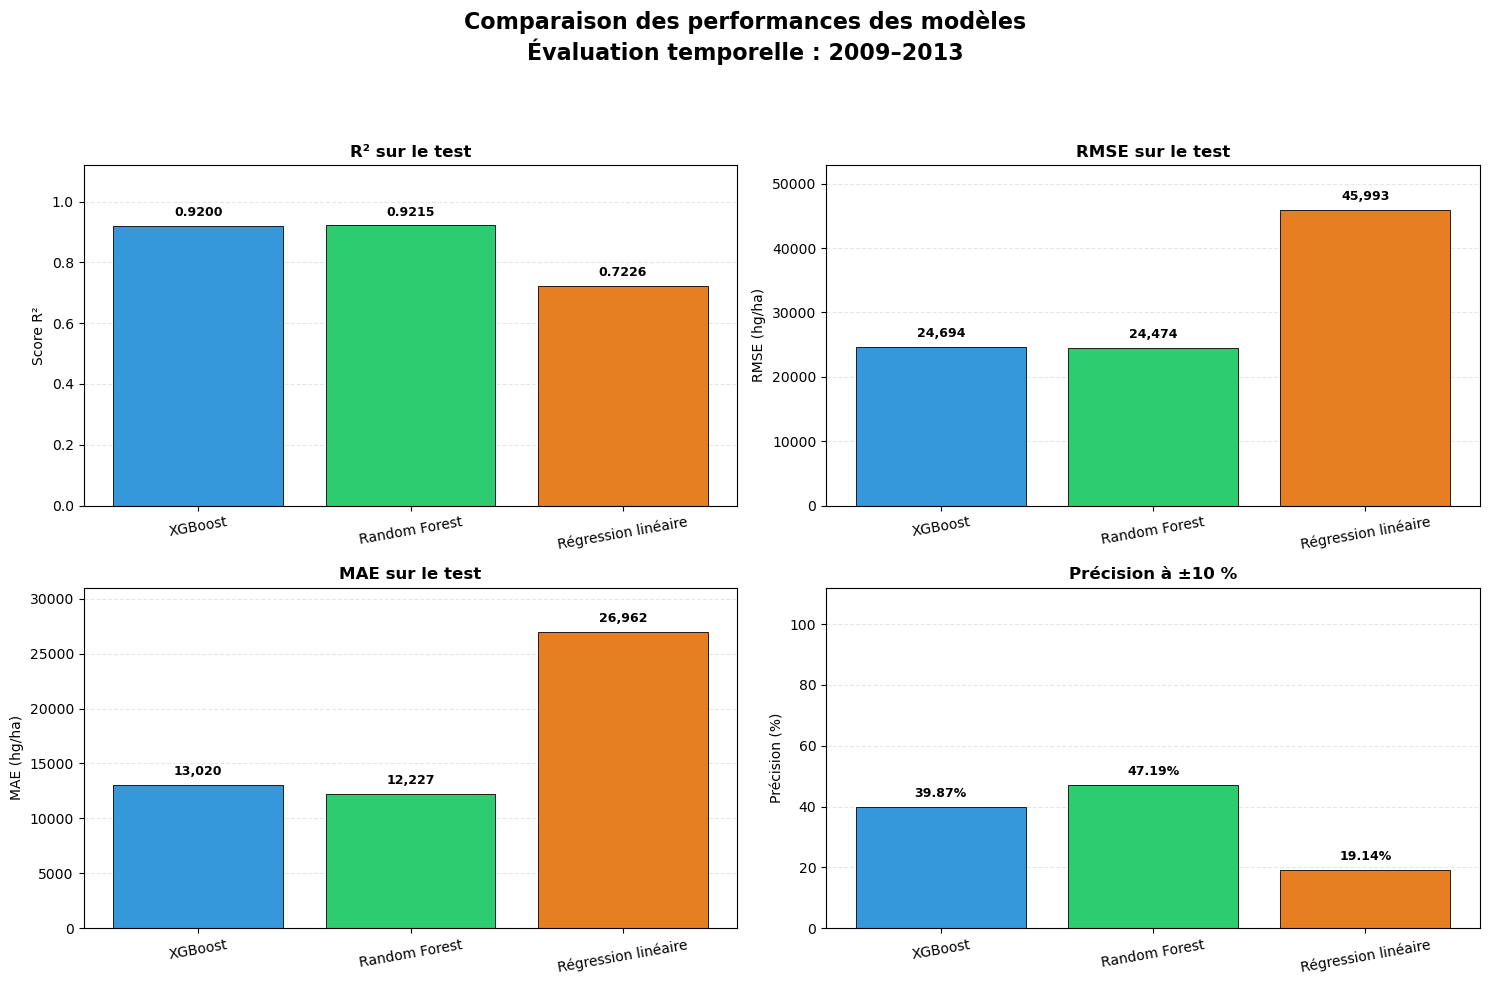

In [68]:


import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# COMPARAISON VISUELLE DES 3 MODÈLES
# Test temporel : 2009-2013
# ============================================================

modeles = [
    "XGBoost",
    "Random Forest",
    "Régression linéaire"
]

couleurs = [
    "#3498DB",  # Bleu
    "#2ECC71",  # Vert
    "#E67E22"   # Orange
]

# Métriques sur le jeu de test
r2_test = [0.9200, 0.9215, 0.7226]
rmse_test = [24693.66, 24474.38, 45992.54]
mae_test = [13019.90, 12226.57, 26962.35]
precision_test = [39.87, 47.19, 19.14]

# Créer 4 graphiques
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle(
    "Comparaison des performances des modèles\n"
    "Évaluation temporelle : 2009–2013",
    fontsize=16,
    fontweight="bold"
)

graphiques = [
    (axes[0, 0], r2_test, "R² sur le test", "Score R²", 1.0, "{:.4f}"),
    (axes[0, 1], rmse_test, "RMSE sur le test", "RMSE (hg/ha)", None, "{:,.0f}"),
    (axes[1, 0], mae_test, "MAE sur le test", "MAE (hg/ha)", None, "{:,.0f}"),
    (axes[1, 1], precision_test, "Précision à ±10 %", "Précision (%)", 100, "{:.2f}%")
]

for ax, valeurs, titre, ylabel, ymax, format_label in graphiques:
    barres = ax.bar(
        modeles,
        valeurs,
        color=couleurs,
        edgecolor="black",
        linewidth=0.6
    )

    ax.set_title(titre, fontsize=12, fontweight="bold")
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    ax.set_axisbelow(True)

    if ymax is not None:
        ax.set_ylim(0, ymax * 1.12)
    else:
        ax.set_ylim(0, max(valeurs) * 1.15)

    # Afficher la valeur au-dessus de chaque barre
    for barre, valeur in zip(barres, valeurs):
        ax.annotate(
            format_label.format(valeur),
            xy=(barre.get_x() + barre.get_width() / 2, barre.get_height()),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold"
        )

    ax.tick_params(axis="x", labelrotation=10)

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()


### Exportation du modèle choisi

In [70]:

import joblib
import os

# Créer le dossier model s'il n'existe pas
os.makedirs("../model", exist_ok=True)

# Sauvegarder le modèle entraîné
joblib.dump(rf_pipeline, "../model/model_random_forest.pkl")

print("✅ Modèle Random Forest sauvegardé avec succès !")


✅ Modèle Random Forest sauvegardé avec succès !


In [72]:

# Sauvegarde du modèle XGBoost avec joblib
import joblib
import os

# Créer le dossier s'il n'existe pas
os.makedirs("../model", exist_ok=True)

# Exporter le pipeline XGBoost entraîné
joblib.dump(xgb_pipeline, "../model/model_xgb.pkl")

print("✅ Modèle XGBoost exporté avec succès : ../model/model_xgb.pkl")


✅ Modèle XGBoost exporté avec succès : ../model/model_xgb.pkl


In [74]:
print(os.path.exists("../model/model_xgb.pkl"))

True


In [79]:
import mlflow
import os

print("Version MLflow :", mlflow.__version__)
print("Dossier courant :", os.getcwd())
print("URI de tracking :", mlflow.get_tracking_uri())


Version MLflow : 3.6.0
Dossier courant : C:\Users\amela\P12 System recomendation
URI de tracking : mlruns


In [81]:

import os

chemin_modele = os.path.abspath("../model/model_xgb.pkl")

print("Chemin du modèle :", chemin_modele)
print("Fichier existant :", os.path.isfile(chemin_modele))

if os.path.isfile(chemin_modele):
    print("Taille du fichier :", round(os.path.getsize(chemin_modele) / 1024, 2), "Ko")


Chemin du modèle : C:\Users\amela\model\model_xgb.pkl
Fichier existant : True
Taille du fichier : 3427.51 Ko


In [83]:

import joblib
import numpy as np
import os

# Charger le modèle sauvegardé
chemin = r"C:\Users\amela\model\model_xgb.pkl"
model = joblib.load(chemin)

print("✅ Modèle XGBoost chargé avec succès !")
print("Type :", type(model))

# Vérifier que le pipeline possède une méthode de prédiction
print("Méthode predict disponible :", hasattr(model, "predict"))


✅ Modèle XGBoost chargé avec succès !
Type : <class 'sklearn.pipeline.Pipeline'>
Méthode predict disponible : True


In [85]:

import joblib
import pandas as pd
import numpy as np

# 1. Charger le modèle sauvegardé
chemin_modele = r"C:\Users\amela\model\model_xgb.pkl"
model = joblib.load(chemin_modele)

# 2. Préparer un exemple de données
nouvelle_donnee = pd.DataFrame([{
    "Year": 2013,
    "average_rain_fall_mm_per_year": 1200,
    "avg_temp": 20.5,
    "Pesticide_totale_use_tonnes": 5000,
    "Area": "France",
    "Item": "Maize"
}])

# 3. Effectuer la prédiction
prediction_log = model.predict(nouvelle_donnee)

# 4. Revenir à l'échelle originale du rendement
prediction_rendement = np.expm1(prediction_log[0])

print("✅ Prédiction réalisée avec succès !")
print(f"Rendement prédit : {prediction_rendement:,.2f} hg/ha")
print(f"Soit environ : {prediction_rendement / 100:,.2f} kg/ha")


✅ Prédiction réalisée avec succès !
Rendement prédit : 22,158.22 hg/ha
Soit environ : 221.58 kg/ha
